# Exploratory Data Analysis: U.S. Interest Rates and Housing Market

The goal of this analysis is to explore the relationship between U.S. interest rates and housing market activity from 2000 to 2026. I focus on the federal funds rate, 30-year mortgage rate, housing starts, and new home sales.

The analysis examines correlations, differences between high- and low-rate periods, and annual trends to better understand how these indicators move together over time.

In [47]:
import pandas as pd
from pathlib import Path

In [48]:
processed_data = Path("../data/processed")

In [49]:
df = pd.read_csv(
    processed_data / "merged_housing_interest_rates_2000_2026.csv"
)


In [50]:
df.dtypes

date               object
fed_funds_rate    float64
mortgage_rate     float64
housing_starts      int64
new_home_sales      int64
dtype: object

In [51]:
df["date"] = pd.to_datetime(
    df["date"]
)

# 1. Data Preparation and Overview

I loaded the merged dataset and converted the date column to datetime format so that observations could be analyzed by month and year. I also checked the data types and descriptive statistics to understand the dataset before investigating relationships between variables.

Housing starts and new home sales are measured in thousands of units at a seasonally adjusted annual rate (SAAR). The 2026 data covers January through August only.

In [52]:
df.dtypes

date              datetime64[ns]
fed_funds_rate           float64
mortgage_rate            float64
housing_starts             int64
new_home_sales             int64
dtype: object

# 2. Descriptive Statistics

I reviewed the mean, standard deviation, and range of each indicator to understand its typical values and variation over the study period. This provides context for interpreting the correlations and group comparisons that follow.

In [53]:
df.describe()

,date,fed_funds_rate,mortgage_rate,housing_starts,new_home_sales
count,320,320.000000,320.000000,320.000000,320.000000
mean,2013-04-16 11:15:00,2.048469,5.235188,1308.965625,695.356250
min,2000-01-01 00:00:00,0.050000,2.680000,478.000000,270.000000
25%,2006-08-24 06:00:00,0.150000,3.977500,1038.500000,481.500000
50%,2013-04-16 00:00:00,1.375000,5.225000,1320.000000,650.000000
75%,2019-12-08 18:00:00,3.895000,6.352500,1600.000000,880.500000
max,2026-08-01 00:00:00,6.540000,8.520000,2273.000000,1389.000000
std,NaN,2.022276,1.389173,418.839884,268.036453


# 3. Monthly Correlation Analysis

I calculated a correlation matrix to examine the strength and direction of linear relationships among interest rates and housing market indicators. Pearson correlation coefficients range from -1 to +1, with values closer to either extreme indicating stronger linear relationships.

The matrix helps identify which indicators tend to move together over the monthly observations. However, correlation measures association rather than causation, so the results should be interpreted alongside broader economic conditions.

In [54]:
df[
    ["fed_funds_rate","mortgage_rate", "housing_starts","new_home_sales"]
].corr()

,fed_funds_rate,mortgage_rate,housing_starts,new_home_sales
fed_funds_rate,1.000000,0.820733,0.446793,0.422667
mortgage_rate,0.820733,1.000000,0.390086,0.411494
housing_starts,0.446793,0.390086,1.000000,0.928881
new_home_sales,0.422667,0.411494,0.928881,1.000000


## Interpretation of Monthly Correlations

The federal funds rate and mortgage rate have a strong positive correlation of approximately 0.82. Housing starts and new home sales also show a strong positive correlation of approximately 0.93, indicating that these two measures of housing activity tend to move together.

The positive correlations between interest rates and housing activity are less straightforward to interpret. They may reflect differences across economic cycles rather than a direct relationship in which higher rates correspond to greater housing activity.

# 4. Comparing High- and Low-Rate Periods

To examine whether housing activity differs across interest rate environments, I divided the monthly observations into high- and low-rate groups using the median federal funds rate as the cutoff.

I compared average housing starts and new home sales between the groups. This approach provides a straightforward comparison, although it does not control for other factors such as economic growth, housing supply, or changes in demand.

In [55]:
median_rate = df["fed_funds_rate"].median()

high_rate = df[df["fed_funds_rate"] > median_rate].copy()
low_rate = df[df["fed_funds_rate"] <= median_rate].copy()

In [56]:
print("High Rate period averages:", high_rate[["housing_starts", "new_home_sales"]].mean())

High Rate period averages: housing_starts    1495.1625
new_home_sales     806.1000
dtype: float64


In [57]:
print("Low rate period averages:", low_rate[["housing_starts", "new_home_sales"]].mean())

Low rate period averages: housing_starts    1122.76875
new_home_sales     584.61250
dtype: float64


## Interpretation of High- and Low-Rate Periods

The high-rate group had average housing starts of approximately 1,495 thousand and average new home sales of approximately 806 thousand. In comparison, the low-rate group averaged approximately 1,123 thousand housing starts and 585 thousand new home sales.

Both housing indicators had higher averages in the high-rate group. This result differs from the simple expectation that lower interest rates should always correspond to greater housing activity. However, the comparison groups include different economic periods and do not account for other factors that affect the housing market. Therefore, these averages do not demonstrate that higher interest rates increase housing activity.

# 5. Annual Trend Analysis

I aggregated the monthly observations into annual averages to examine longer-term patterns and reduce month-to-month variation. This allows me to compare broad movements in interest rates and housing market activity over time.

Because the 2026 data only covers January through August, its annual average is not directly comparable to a complete calendar year.

In [58]:
df["year"] = df["date"].dt.year

yearly_data = df.groupby("year")[
    ["fed_funds_rate", "mortgage_rate",
     "housing_starts", "new_home_sales"]
].mean()

In [59]:
yearly_data.head()

,fed_funds_rate,mortgage_rate,housing_starts,new_home_sales
year,,,,
2000,6.235833,8.063333,1573.333333,880.250000
2001,3.887500,6.972500,1601.166667,907.250000
2002,1.666667,6.537500,1710.250000,976.166667
2003,1.127500,5.819167,1853.750000,1090.666667
2004,1.349167,5.839167,1949.500000,1200.833333


In [60]:
yearly_data.shape

(27, 4)

In [61]:
import matplotlib.pyplot as plt

## Federal Funds Rate and Mortgage Rate Trends

I plotted the annual average federal funds rate and mortgage rate together to visually compare their movements over time. This helps identify periods when the two rates moved in similar or different directions.

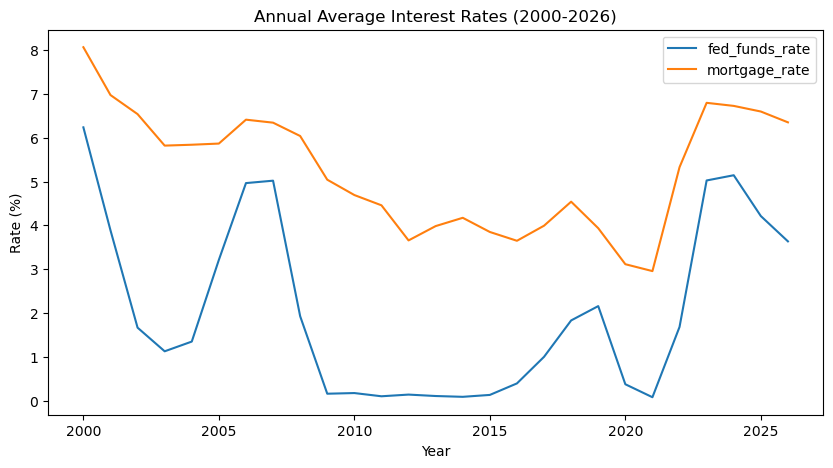

In [62]:
yearly_data[["fed_funds_rate", "mortgage_rate"]].plot(
    figsize=(10, 5)
)

plt.title("Annual Average Interest Rates (2000-2026)")
plt.xlabel("Year")
plt.ylabel("Rate (%)")
plt.show()

## Years with the Highest and Lowest Federal Funds Rates

I identified the years with the highest and lowest annual average federal funds rates and examined the corresponding mortgage rates and housing indicators. Comparing these years provides additional context, although two individual years cannot represent the full relationship across the entire period.

In [63]:
highest_rate_year = yearly_data["fed_funds_rate"].idxmax()
lowest_rate_year = yearly_data["fed_funds_rate"].idxmin()

In [68]:
print("Highest-rate year:", highest_rate_year)
print(yearly_data.loc[highest_rate_year])

print("\n Lowest-rate year:", lowest_rate_year)
print(yearly_data.loc[lowest_rate_year])

Highest-rate year: 2000
fed_funds_rate       6.235833
mortgage_rate        8.063333
housing_starts    1573.333333
new_home_sales     880.250000
Name: 2000, dtype: float64

 Lowest-rate year: 2021
fed_funds_rate       0.080000
mortgage_rate        2.956667
housing_starts    1603.333333
new_home_sales     768.666667
Name: 2021, dtype: float64


## Annual Correlation Analysis

I recalculated the correlation matrix using annual averages to see whether the relationships observed in monthly data remain similar after aggregation. The results can differ because annual averages smooth short-term fluctuations and provide fewer observations.

In [66]:
yearly_data[
    ["fed_funds_rate", "mortgage_rate", "housing_starts", "new_home_sales"]
].corr()

,fed_funds_rate,mortgage_rate,housing_starts,new_home_sales
fed_funds_rate,1.000000,0.844174,0.477844,0.444832
mortgage_rate,0.844174,1.000000,0.425907,0.447839
housing_starts,0.477844,0.425907,1.000000,0.954339
new_home_sales,0.444832,0.447839,0.954339,1.000000


## Comparing Monthly and Annual Relationships

Comparing monthly and annual correlation matrices revealed similar patterns across both time scales. The correlation between the federal funds rate and mortgage rate increased from approximately 0.82 monthly to 0.84 annually. The relationship between housing starts and new home sales was also stronger in the annual data, increasing from approximately 0.93 to 0.95.

The correlations between interest rates and housing activity were positive in both datasets, but generally weaker than the correlations between the two interest rates or between the two housing indicators. This suggests that housing activity is associated with interest rates, but the relationship is less direct and may be influenced by other economic factors.

Overall, the similar correlation patterns suggest that these relationships are not limited to short-term monthly fluctuations. However, annual aggregation reduces the number of observations, and neither monthly nor annual correlations establish causation.

# 6. Key Findings and Limitations

This analysis identified three main patterns. First, the federal funds rate and 30-year mortgage rate showed a strong positive correlation in both monthly and annual data. Second, housing starts and new home sales were also strongly correlated, with an even stronger relationship in the annual data. Third, average housing activity was higher in the high-rate group than in the low-rate group, showing that the relationship between interest rates and housing activity is more complex than a simple inverse pattern.

Several limitations should be considered. Correlations and group averages do not establish causation, and the analysis does not control for economic growth, housing supply, affordability, or population changes. In addition, the 2026 observations cover only January through August. Future analysis could examine lagged relationships to investigate whether housing activity responds to interest rate changes over time.